In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, f1_score, recall_score

In [7]:
df = pd.read_csv("loan_approval_data.csv")

In [8]:
df.shape

(1000, 20)

In [9]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


# HANDLE MISSING VALUES

WE WILL USE MEAN TO FILL NUMERICAL DATA 
for categorical data we will use the most_frequent in sklearn imputer

In [10]:
categorical_col = df.select_dtypes(include=["object", "str"]).columns
numerical_col = df.select_dtypes(include=["number"]).columns

In [11]:
num_imp = SimpleImputer(strategy = "mean")
df[numerical_col] = num_imp.fit_transform(df[numerical_col])
cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_col] = cat_imp.fit_transform(df[categorical_col])

# EDA

In [12]:
class_counts = df["Loan_Approved"].value_counts()

Text(0.5, 1.0, 'is loan approved or not')

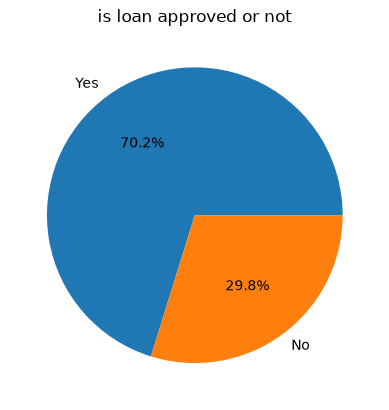

In [13]:
plt.pie(class_counts, labels = ["Yes","No"], autopct = "%1.1f%%")
plt.title("is loan approved or not")

<Axes: xlabel='Applicant_Income', ylabel='Count'>

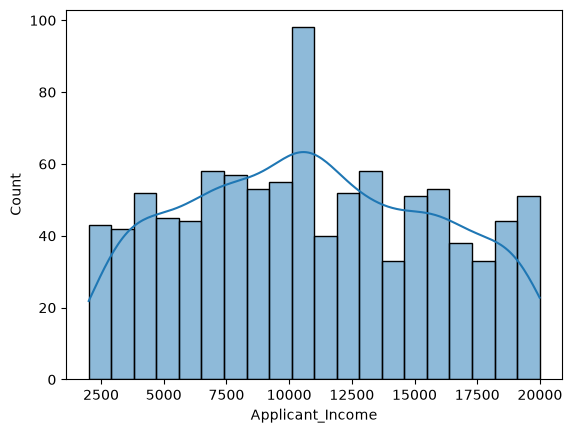

In [14]:
sns.histplot(data = df ,  x ="Applicant_Income" , bins = 20 , kde = True )

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

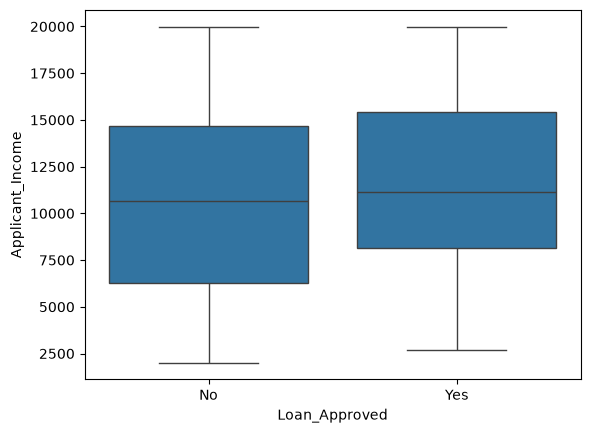

In [15]:
sns.boxplot(data = df, x= "Loan_Approved" , y = "Applicant_Income")

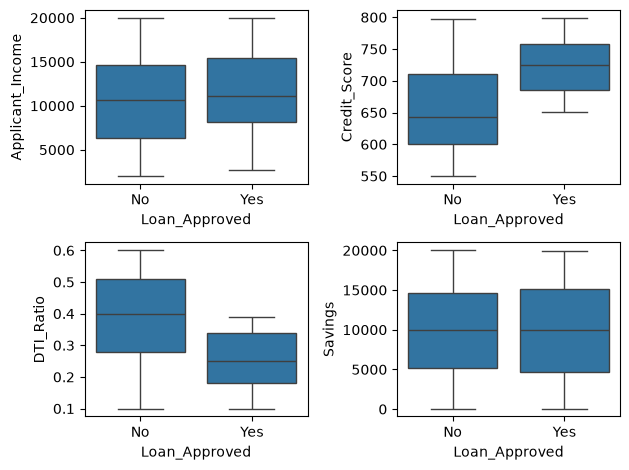

In [16]:
fig, axes = plt.subplots(2,2)
sns.boxplot(ax=axes[0,0],data=df, x = "Loan_Approved", y = "Applicant_Income")
sns.boxplot(ax=axes[0,1],data=df, x = "Loan_Approved", y = "Credit_Score")
sns.boxplot(ax=axes[1,0],data=df, x = "Loan_Approved", y = "DTI_Ratio")
sns.boxplot(ax=axes[1,1],data=df, x = "Loan_Approved", y = "Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

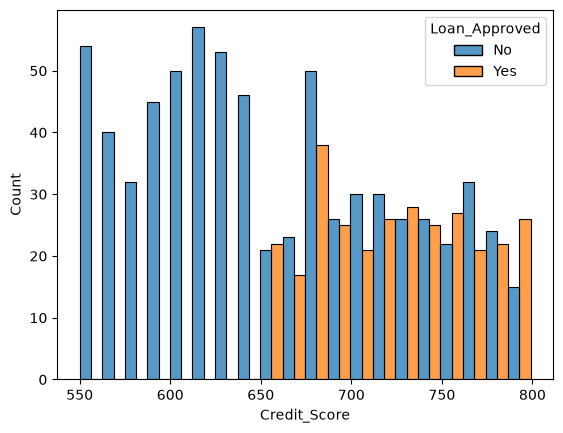

In [17]:
sns.histplot(data = df , x ="Credit_Score", bins = 20 , multiple = "dodge" , hue = "Loan_Approved")

In [18]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1000 non-null   float64
 1   Applicant_Income    1000 non-null   float64
 2   Coapplicant_Income  1000 non-null   float64
 3   Employment_Status   1000 non-null   str    
 4   Age                 1000 non-null   float64
 5   Marital_Status      1000 non-null   str    
 6   Dependents          1000 non-null   float64
 7   Credit_Score        1000 non-null   float64
 8   Existing_Loans      1000 non-null   float64
 9   DTI_Ratio           1000 non-null   float64
 10  Savings             1000 non-null   float64
 11  Collateral_Value    1000 non-null   float64
 12  Loan_Amount         1000 non-null   float64
 13  Loan_Term           1000 non-null   float64
 14  Loan_Purpose        1000 non-null   str    
 15  Property_Area       1000 non-null   str    
 16  Education_Level   

In [20]:
cols = ["Employment_Status", "Marital_Status", "Loan_Purpose","Property_Area", "Gender", "Employer_Category"]

In [21]:
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


In [22]:
ohe = OneHotEncoder(drop = "first", sparse_output= False, handle_unknown = "ignore")
encoded = ohe.fit_transform(df[cols])

In [23]:
encoded_df  = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols), index=df.index)

In [24]:
encoded_df.head()

,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [25]:
df = pd.concat([df.drop(columns = cols), encoded_df] , axis =1)

# CORELATION HEATMAP

In [26]:
num_col = df.select_dtypes(include="number").columns
cormatrix = df[num_col].corr()

In [27]:
df[num_col].corr()["Loan_Approved"].sort_values(ascending = False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Applicant_ID                      -0.011167
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed    

<Axes: >

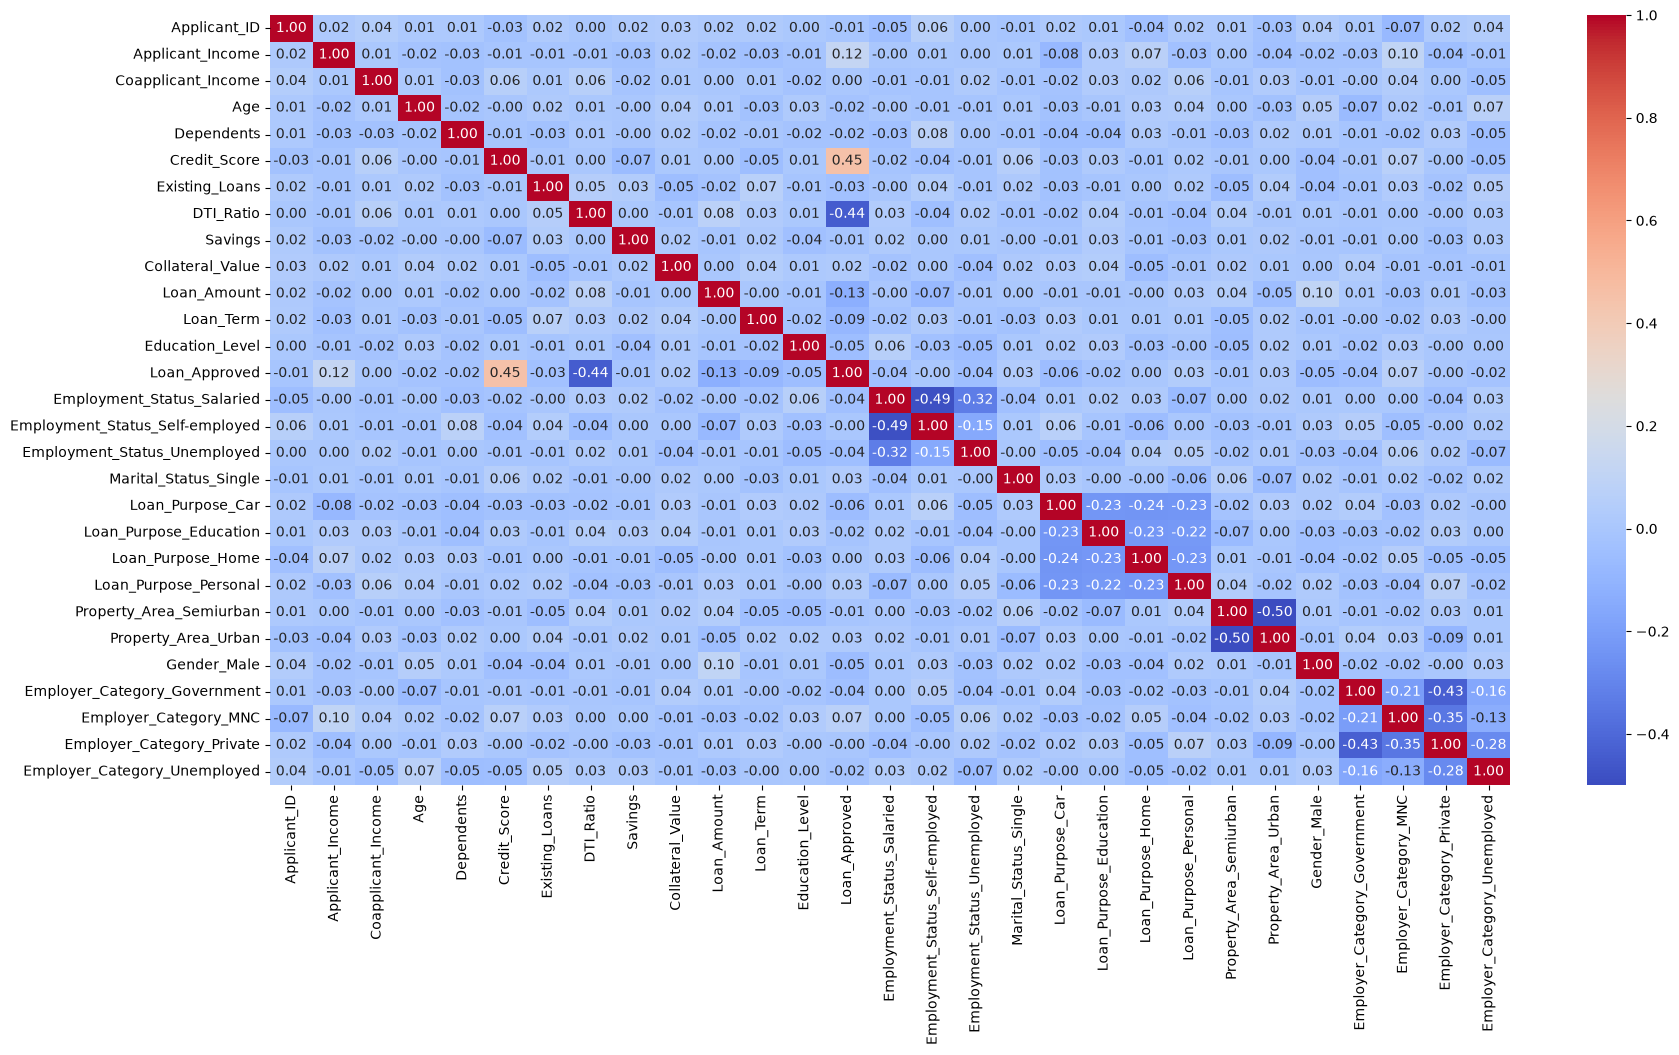

In [28]:
plt.figure(figsize=(20,10))
sns.heatmap(cormatrix, cmap="coolwarm", annot = True, fmt = ".2f",)

In [29]:
X = df.drop("Loan_Approved" ,axis=1)
y = df["Loan_Approved"]

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state = 42 , test_size = 0.20)

In [31]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

# Logestic regression + Evaluation

In [32]:
log_model = LogisticRegression()
log_model.fit(X_train_scale,y_train)

y_predict = log_model.predict(X_test_scale)

print("precision_score :" , precision_score(y_test,y_predict))
print("recall_score :" , recall_score(y_test,y_predict))
print("f1_score :" , f1_score(y_test,y_predict))
print("accuracy_score :" , accuracy_score(y_test,y_predict))
print("confuson_metrix :" , confusion_matrix(y_test,y_predict))

precision_score : 0.7868852459016393
recall_score : 0.7868852459016393
f1_score : 0.7868852459016393
accuracy_score : 0.87
confuson_metrix : [[126  13]
 [ 13  48]]


# KNN

In [37]:
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(X_train_scale,y_train)

y_predict = knn.predict(X_test_scale)

print("precision_score :" , precision_score(y_test,y_predict))
print("recall_score :" , recall_score(y_test,y_predict))
print("f1_score :" , f1_score(y_test,y_predict))
print("accuracy_score :" , accuracy_score(y_test,y_predict))
print("accuracy_score :" , accuracy_score(y_test,y_predict))
print("confuson_metrix :" , confusion_matrix(y_test,y_predict))

precision_score : 0.5957446808510638
recall_score : 0.45901639344262296
f1_score : 0.5185185185185185
accuracy_score : 0.74
accuracy_score : 0.74
confuson_metrix : [[120  19]
 [ 33  28]]


# Naive bayes

In [38]:
nb =  GaussianNB()
nb.fit(X_train_scale,y_train)

y_predict = nb.predict(X_test_scale)

print("precision_score :" , precision_score(y_test,y_predict))
print("recall_score :" , recall_score(y_test,y_predict))
print("f1_score :" , f1_score(y_test,y_predict))
print("accuracy_score :" , accuracy_score(y_test,y_predict))
print("confuson_metrix :" , confusion_matrix(y_test,y_predict))

precision_score : 0.8035714285714286
recall_score : 0.7377049180327869
f1_score : 0.7692307692307693
accuracy_score : 0.865
confuson_metrix : [[128  11]
 [ 16  45]]
